# Machine Learning-Based Transmission Line Fault Type Classification for Intelligent Power System Protection
**Course:** Energy System Analytics (EE 1331)  
**Project No.:** 15  
**Students:** Rishabh Raturi (24EEB0A55), Simhadri Yateesh Sai (24EEB0A59)  
**Faculty:** Prof. Debasmita Panda  
**Department:** Electrical & Electronics Engineering, 5th Sem 2026–2027

---
### Step 3: Set up Python Environment and Load Dataset
In this step, we import the necessary scientific computing, machine learning, and visualization libraries.

In [15]:
# Install dependencies if running on Google Colab or fresh environment:
# !pip install pandas numpy scikit-learn matplotlib seaborn joblib

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10

# Load dataset
dataset_file = 'fault_dataset.csv'
df_raw = pd.read_csv(dataset_file)
print(f"Dataset successfully loaded: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns.")

Dataset successfully loaded: 618 rows, 27 columns.


### Step 4: Data Inspection & Preprocessing (Sections 2.2 and 3)
We inspect dataset dimensions, feature types, missing values, duplicates, and class balance.

In [16]:
# Inspect head, info, and describe
# Data Cleaning and Preprocessing
print("=== Dataset Head (First 5 Rows) ===")
display(df_raw.head())

print("\n=== Dataset Information ===")
df_raw.info()

print("\n=== Summary Statistics ===")
display(df_raw.describe())

print("\n=== Missing Values Scan ===")
print(df_raw.isnull().sum())

print("\n=== Class Distribution (Raw) ===")
print(df_raw['fault'].value_counts())

=== Dataset Head (First 5 Rows) ===


,Ua1,Ub1,Uc1,Ua2,Ub2,Uc2,Ua3,Ub3,Uc3,Ia1,...,Ic3,Ia4,Ib4,Ic4,Ia5,Ib5,Ic5,fault,line,position
0,7.722,7.722,7.722,0.000,0.000,0.000,3.770,3.770,3.770,11.539,...,1.205,1.205,1.205,1.205,0.372,0.372,0.372,3psc,Line1,0.0
1,15.919,15.919,15.919,9.855,9.855,9.855,10.163,10.163,10.163,9.718,...,0.954,0.954,0.954,0.954,0.543,0.543,0.543,3psc,Line1,5.0
2,21.787,21.787,21.787,16.948,16.948,16.948,14.563,14.563,14.563,8.356,...,0.763,0.763,0.763,0.763,0.680,0.680,0.680,3psc,Line1,10.0
3,26.106,26.106,26.106,22.224,22.224,22.224,17.636,17.636,17.636,7.305,...,0.613,0.613,0.613,0.613,0.797,0.797,0.797,3psc,Line1,15.0
4,29.355,29.355,29.355,26.250,26.250,26.250,19.779,19.779,19.779,6.471,...,0.492,0.492,0.492,0.492,0.900,0.900,0.900,3psc,Line1,20.0



=== Dataset Information ===
<class 'pandas.DataFrame'>
RangeIndex: 618 entries, 0 to 617
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Ua1       618 non-null    float64
 1   Ub1       618 non-null    float64
 2   Uc1       618 non-null    float64
 3   Ua2       618 non-null    float64
 4   Ub2       618 non-null    float64
 5   Uc2       618 non-null    float64
 6   Ua3       618 non-null    float64
 7   Ub3       618 non-null    float64
 8   Uc3       618 non-null    float64
 9   Ia1       618 non-null    float64
 10  Ib1       618 non-null    float64
 11  Ic1       618 non-null    float64
 12  Ia2       618 non-null    float64
 13  Ib2       618 non-null    float64
 14  Ic2       618 non-null    float64
 15  Ia3       618 non-null    float64
 16  Ib3       618 non-null    float64
 17  Ic3       618 non-null    float64
 18  Ia4       618 non-null    float64
 19  Ib4       618 non-null    float64
 20  Ic4       618 

,Ua1,Ub1,Uc1,Ua2,Ub2,Uc2,Ua3,Ub3,Uc3,Ia1,...,Ia3,Ib3,Ic3,Ia4,Ib4,Ic4,Ia5,Ib5,Ic5,position
count,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,...,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,618.000000,315.000000
mean,51.581285,54.947081,53.804652,50.935477,56.172249,55.051474,47.117403,52.715511,51.921225,0.405739,...,0.606123,0.773626,0.776602,0.606123,0.773626,0.776602,0.625594,0.688112,0.690367,50.000000
std,21.281078,18.890918,19.357012,20.913795,18.027623,19.120814,24.268274,21.615220,22.065604,1.092913,...,1.298188,1.477578,1.470225,1.298188,1.477578,1.470225,1.234103,1.256887,1.257678,30.324676
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.004000,...,0.025000,0.031000,0.033000,0.025000,0.031000,0.033000,0.010000,0.010000,0.010000,0.000000
25%,36.306000,41.139000,37.673000,35.222000,44.041750,38.657000,17.347000,39.550000,35.564000,0.081000,...,0.161000,0.164000,0.164000,0.161000,0.164000,0.164000,0.193000,0.195000,0.195000,25.000000
50%,63.509000,63.509000,63.509000,62.596000,62.596000,62.596000,61.527500,61.527500,61.527500,0.083000,...,0.165000,0.169000,0.169000,0.165000,0.169000,0.169000,0.198000,0.201000,0.203000,50.000000
75%,63.509000,63.509000,63.509000,62.627000,62.627000,62.627000,61.563000,61.563000,61.563000,0.144000,...,0.306750,0.689000,0.728000,0.306750,0.689000,0.728000,0.338000,0.389000,0.389000,75.000000
max,72.435000,77.295000,77.860000,71.869000,86.224000,89.978000,72.125000,85.988000,84.373000,11.539000,...,10.519000,10.519000,10.519000,10.519000,10.519000,10.519000,8.878000,8.878000,8.878000,100.000000



=== Missing Values Scan ===
Ua1           0
Ub1           0
Uc1           0
Ua2           0
Ub2           0
Uc2           0
Ua3           0
Ub3           0
Uc3           0
Ia1           0
Ib1           0
Ic1           0
Ia2           0
Ib2           0
Ic2           0
Ia3           0
Ib3           0
Ic3           0
Ia4           0
Ib4           0
Ic4           0
Ia5           0
Ib5           0
Ic5           0
fault         0
line        303
position    303
dtype: int64

=== Class Distribution (Raw) ===
fault
no fault    303
3psc        105
2psc        105
spgf        105
Name: count, dtype: int64


In [17]:
# Handling Missing Values & Duplicates
# 1. Feature separation: 24 electrical measurement features
feature_cols = [c for c in df_raw.columns if c not in ['fault', 'line', 'position']]
LABEL = 'fault'

# 2. Drop 73 redundant identical rows in normal load flow
df_clean = df_raw.drop_duplicates().copy()
print(f"Shape after removing identical static load-flow duplicates: {df_clean.shape}")
print("\nClean Class Distribution:")
print(df_clean[LABEL].value_counts())

# Note on Outliers:
# High current spikes (up to 11.54 kA) and deep voltage sags are NOT removed as outliers.
# They represent the physical short-circuit signatures required for fault detection.

X = df_clean[feature_cols].copy()
y = df_clean[LABEL].copy()

# Label Encoding
le = LabelEncoder()
y_enc = le.fit_transform(y)
print("\nClass Encoding Mapping:", dict(enumerate(le.classes_)))

Shape after removing identical static load-flow duplicates: (545, 27)

Clean Class Distribution:
fault
no fault    230
3psc        105
2psc        105
spgf        105
Name: count, dtype: int64

Class Encoding Mapping: {0: '2psc', 1: '3psc', 2: 'no fault', 3: 'spgf'}


### Step 5: Exploratory Data Analysis (EDA) (Section 4)
We generate the 5 required diagnostic visualizations:
1. Class distribution bar chart
2. Histograms / KDE distributions per class
3. Feature correlation heatmap
4. Voltage sag and current inrush box plots
5. 2D PCA scatter plot showing class separability

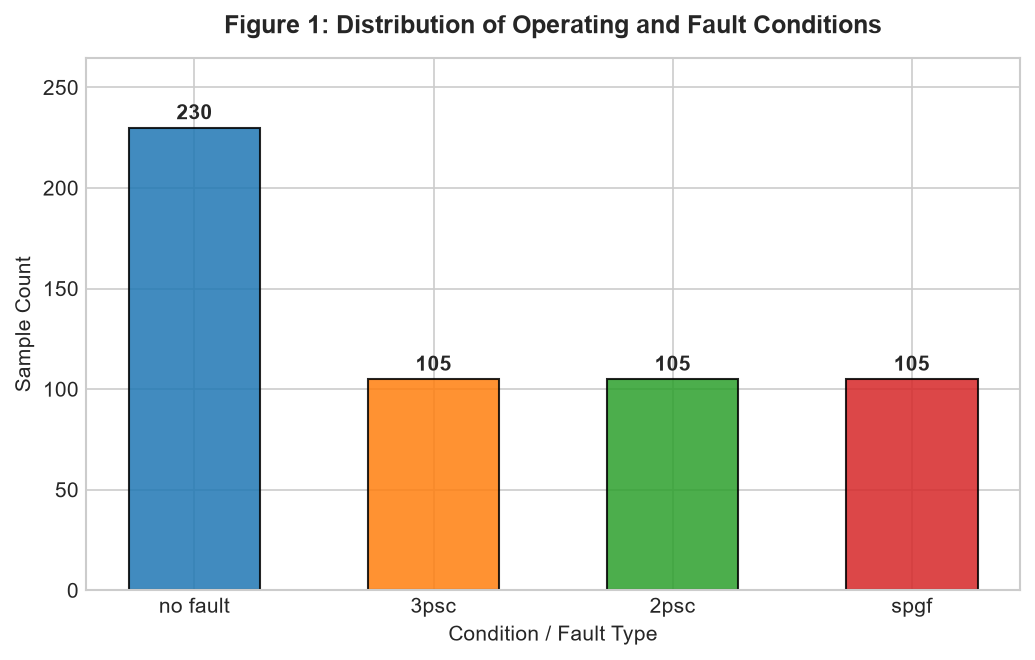

In [18]:
# 1. Class Distribution Bar Chart
# Exploratory Data Analysis
plt.figure(figsize=(7, 4.5), dpi=150)
counts = df_clean[LABEL].value_counts()
bars = plt.bar(counts.index, counts.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], edgecolor='black', alpha=0.85, width=0.55)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')
plt.title('Figure 1: Distribution of Operating and Fault Conditions', fontweight='bold', pad=12)
plt.xlabel('Condition / Fault Type')
plt.ylabel('Sample Count')
plt.ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()

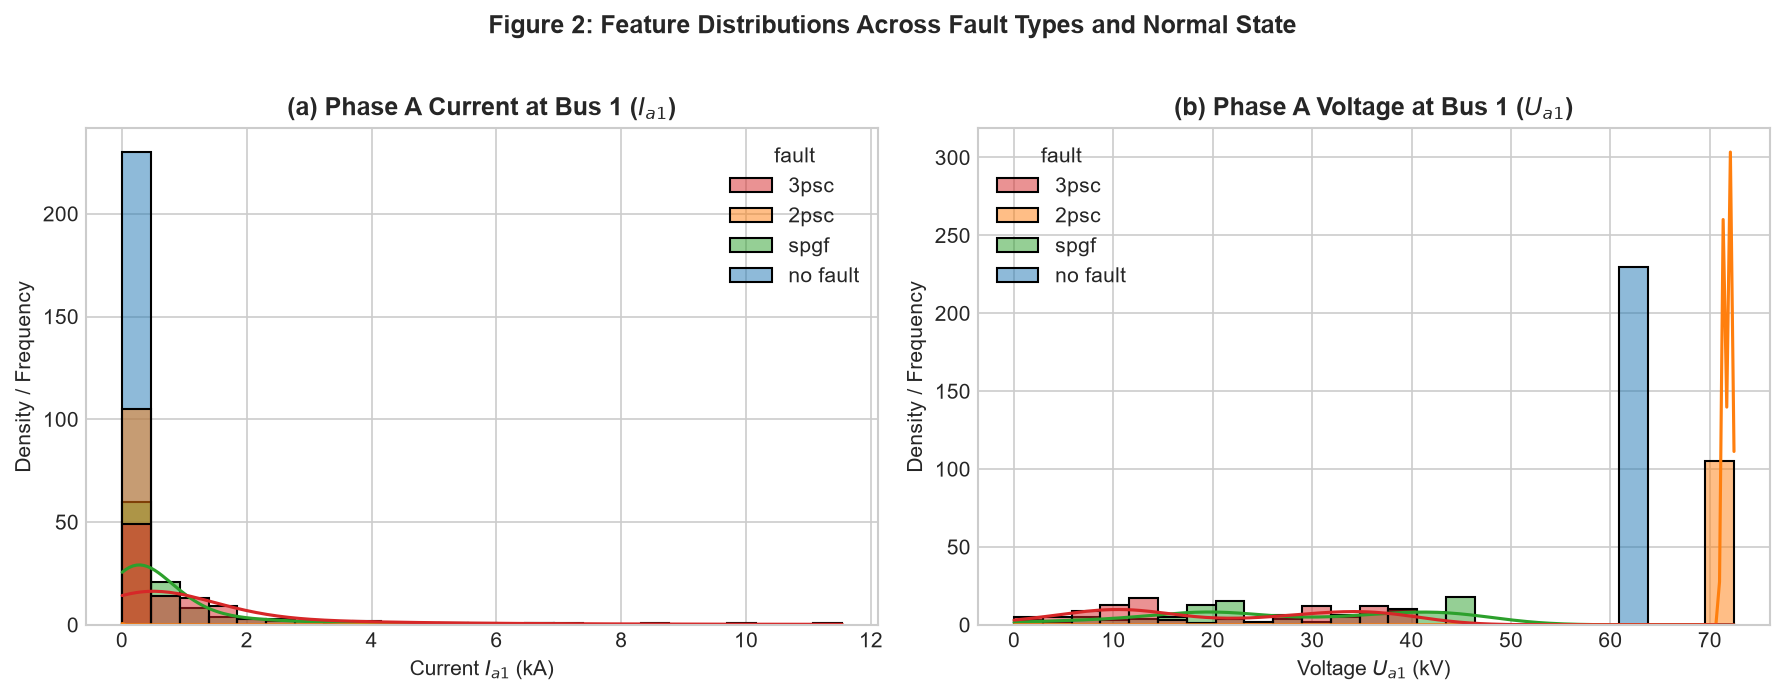

In [19]:
# 2. Histograms / KDE of Key Current and Voltage Channels
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)
palette = {'no fault': '#1f77b4', '3psc': '#d62728', '2psc': '#ff7f0e', 'spgf': '#2ca02c'}

sns.histplot(data=df_clean, x='Ia1', hue=LABEL, kde=True, ax=axes[0], palette=palette, bins=25, alpha=0.5)
axes[0].set_title('(a) Phase A Current at Bus 1 ($I_{a1}$)', fontweight='bold')
axes[0].set_xlabel('Current $I_{a1}$ (kA)')
axes[0].set_ylabel('Density / Frequency')

sns.histplot(data=df_clean, x='Ua1', hue=LABEL, kde=True, ax=axes[1], palette=palette, bins=25, alpha=0.5)
axes[1].set_title('(b) Phase A Voltage at Bus 1 ($U_{a1}$)', fontweight='bold')
axes[1].set_xlabel('Voltage $U_{a1}$ (kV)')
axes[1].set_ylabel('Density / Frequency')

fig.suptitle('Figure 2: Feature Distributions Across Fault Types and Normal State', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

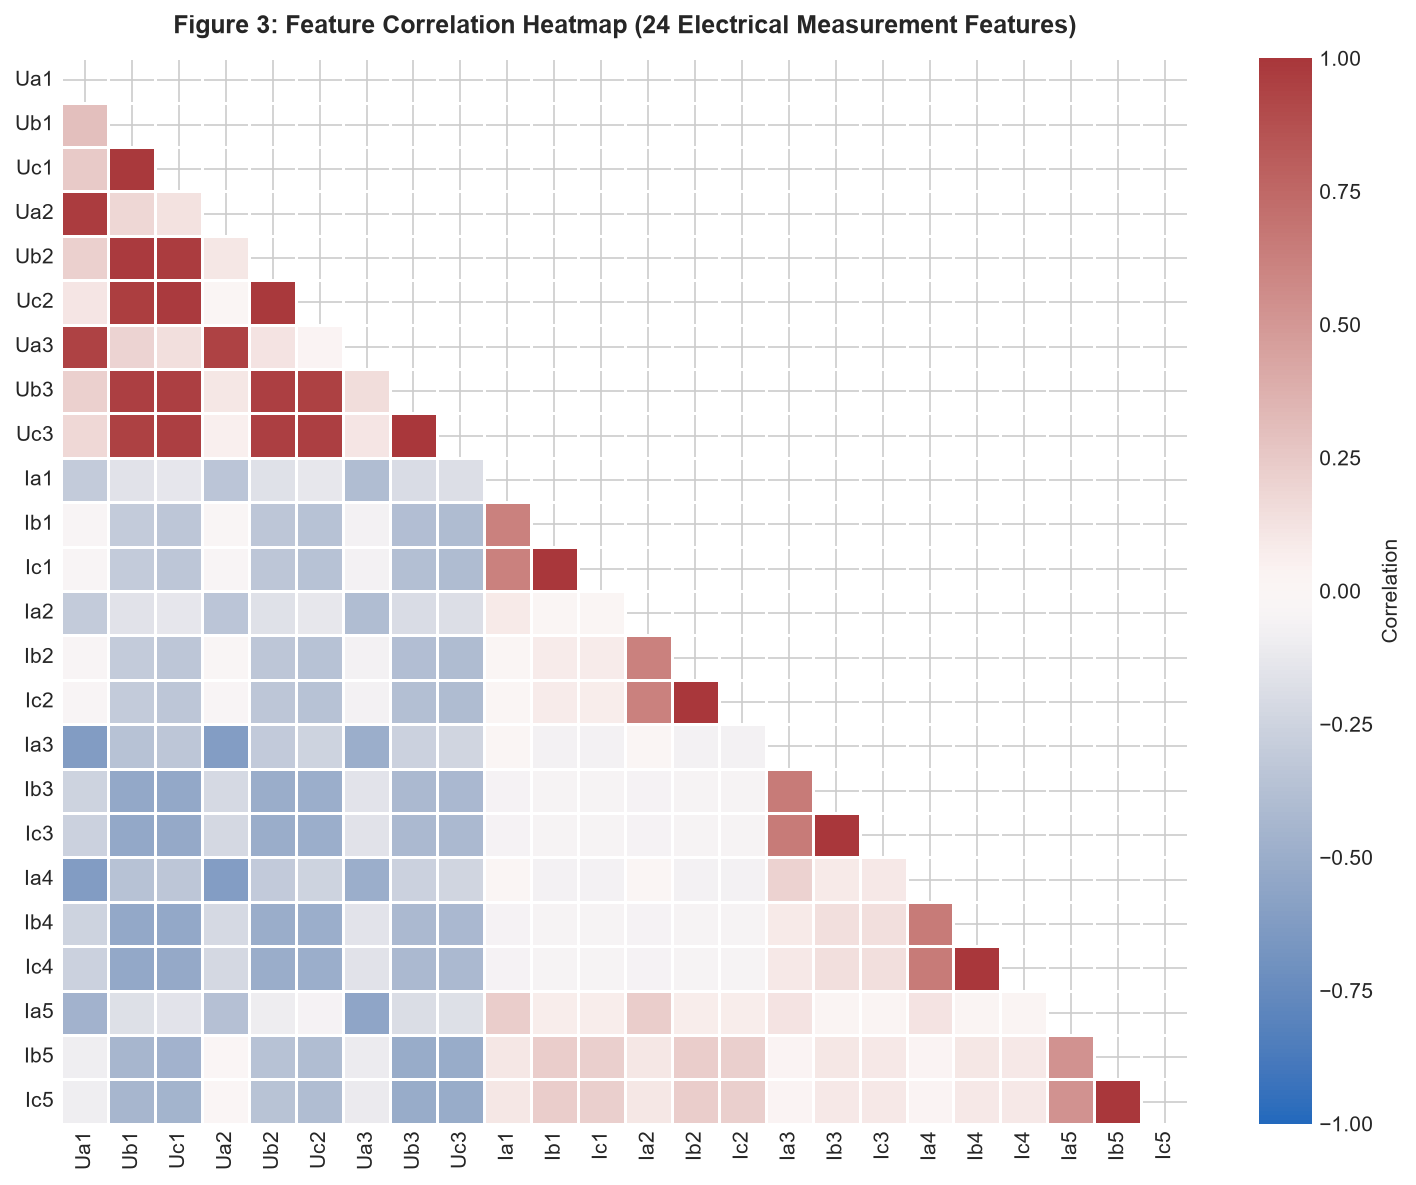

In [20]:
# 3. Pearson Correlation Heatmap
plt.figure(figsize=(10, 8), dpi=150)
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='vlag', vmin=-1, vmax=1, annot=False, linewidths=0.5, cbar_kws={'label': 'Correlation'})
plt.title('Figure 3: Feature Correlation Heatmap (24 Electrical Measurement Features)', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

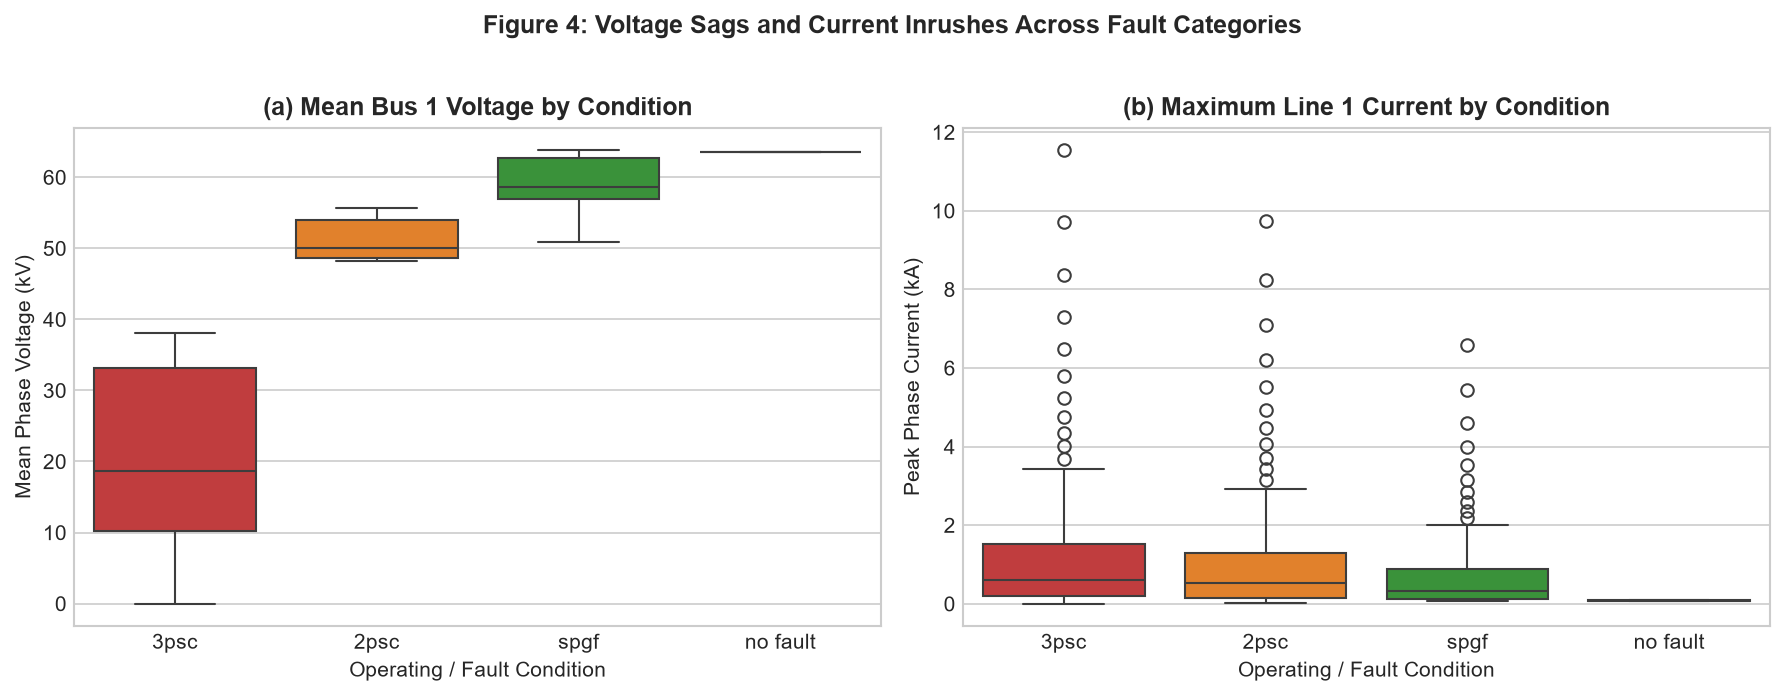

In [21]:
# 4. Box Plots of Voltage Sags and Current Inrushes
df_clean['U_mean'] = df_clean[['Ua1', 'Ub1', 'Uc1']].mean(axis=1)
df_clean['I_max'] = df_clean[['Ia1', 'Ib1', 'Ic1']].max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)
sns.boxplot(data=df_clean, x=LABEL, y='U_mean', ax=axes[0], hue=LABEL, palette=palette, legend=False)
axes[0].set_title('(a) Mean Bus 1 Voltage by Condition', fontweight='bold')
axes[0].set_xlabel('Operating / Fault Condition')
axes[0].set_ylabel('Mean Phase Voltage (kV)')

sns.boxplot(data=df_clean, x=LABEL, y='I_max', ax=axes[1], hue=LABEL, palette=palette, legend=False)
axes[1].set_title('(b) Maximum Line 1 Current by Condition', fontweight='bold')
axes[1].set_xlabel('Operating / Fault Condition')
axes[1].set_ylabel('Peak Phase Current (kA)')

fig.suptitle('Figure 4: Voltage Sags and Current Inrushes Across Fault Categories', fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

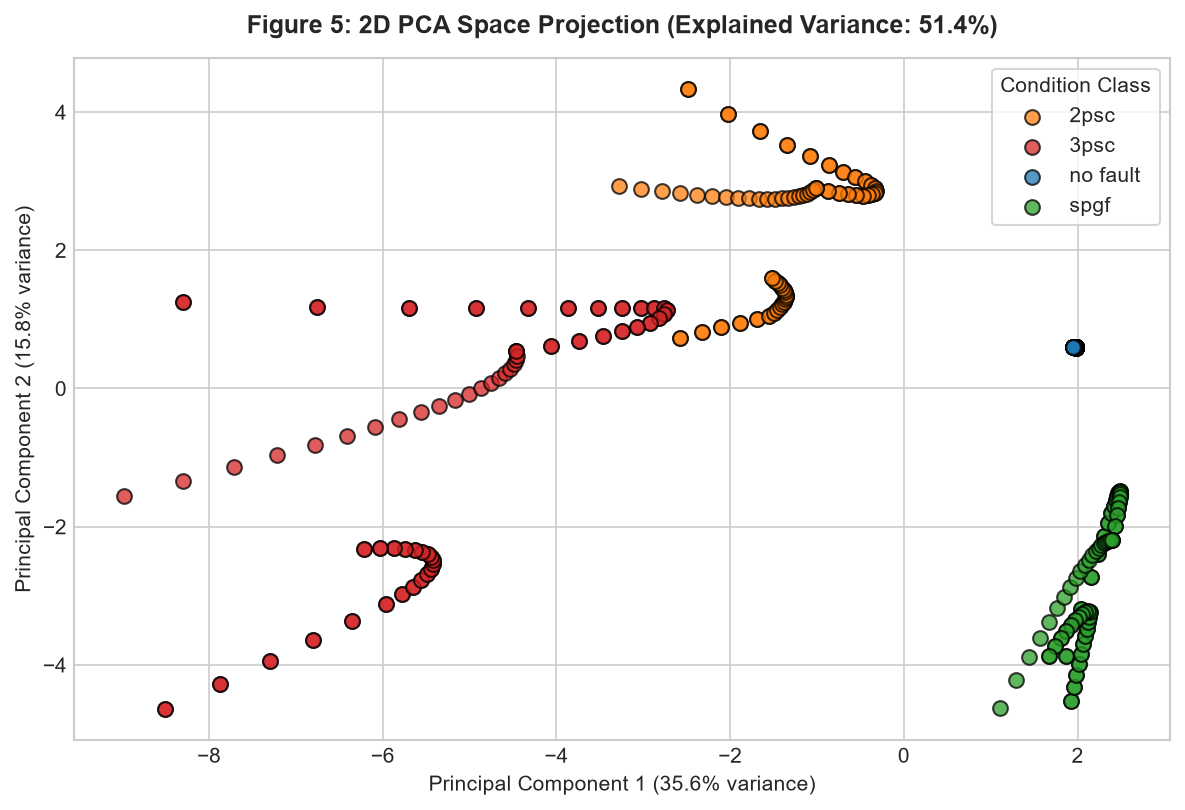

In [22]:
# 5. 2D PCA Scatter Plot
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

plt.figure(figsize=(8, 5.5), dpi=150)
for c_idx, c_name in enumerate(le.classes_):
    mask_c = (y_enc == c_idx)
    plt.scatter(X_pca[mask_c, 0], X_pca[mask_c, 1], label=c_name, color=palette[c_name], alpha=0.75, edgecolors='k', s=50)
plt.title(f'Figure 5: 2D PCA Space Projection (Explained Variance: {var_exp.sum()*100:.1f}%)', fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({var_exp[0]*100:.1f}% variance)')
plt.ylabel(f'Principal Component 2 ({var_exp[1]*100:.1f}% variance)')
plt.legend(title='Condition Class', frameon=True)
plt.tight_layout()
plt.show()

### Step 6: Train the Support Vector Machine (Sections 5 and 7)
We implement the 70/15/15 stratified train/validation/test split and optimize the SVM hyperparameters using 5-fold cross-validation with `GridSearchCV`.

In [23]:
# Stratified 70/15/15 Data Split
# Training, Validation, and Testing Strategy
X_train, X_temp, y_train, y_temp = train_test_split(X, y_enc, test_size=0.30, stratify=y_enc, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(f"Training set samples:   {len(X_train)} (70%)")
print(f"Validation set samples: {len(X_val)} (15%)")
print(f"Testing set samples:    {len(X_test)} (15%)")

# Pipeline with StandardScaler and SVC
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(probability=True, random_state=42))
])

# Hyperparameter search space
param_grid = {
    'svm__kernel': ['linear', 'rbf'],
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.01, 0.1, 1]
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(pipe_svm, param_grid, cv=cv_strat, scoring='f1_macro', n_jobs=1)
grid_search.fit(X_train, y_train)

print("\n=== Optimal Hyperparameters ===")
print("Best Parameters:", grid_search.best_params_)
print(f"Best 5-Fold Stratified CV Macro F1-Score: {grid_search.best_score_:.4f}")

Training set samples:   381 (70%)
Validation set samples: 82 (15%)
Testing set samples:    82 (15%)


c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\


=== Optimal Hyperparameters ===
Best Parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best 5-Fold Stratified CV Macro F1-Score: 1.0000


c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### Step 7: Model Evaluation (Section 8)
We evaluate the best model on the unseen validation and held-out test sets, generating the classification report and confusion matrix. We also benchmark against Random Forest and K-Nearest Neighbors.

Validation Accuracy: 100.00%
Test Set Accuracy:   100.00%

=== Test Classification Report ===
              precision    recall  f1-score   support

        2psc     1.0000    1.0000    1.0000        16
        3psc     1.0000    1.0000    1.0000        16
    no fault     1.0000    1.0000    1.0000        34
        spgf     1.0000    1.0000    1.0000        16

    accuracy                         1.0000        82
   macro avg     1.0000    1.0000    1.0000        82
weighted avg     1.0000    1.0000    1.0000        82



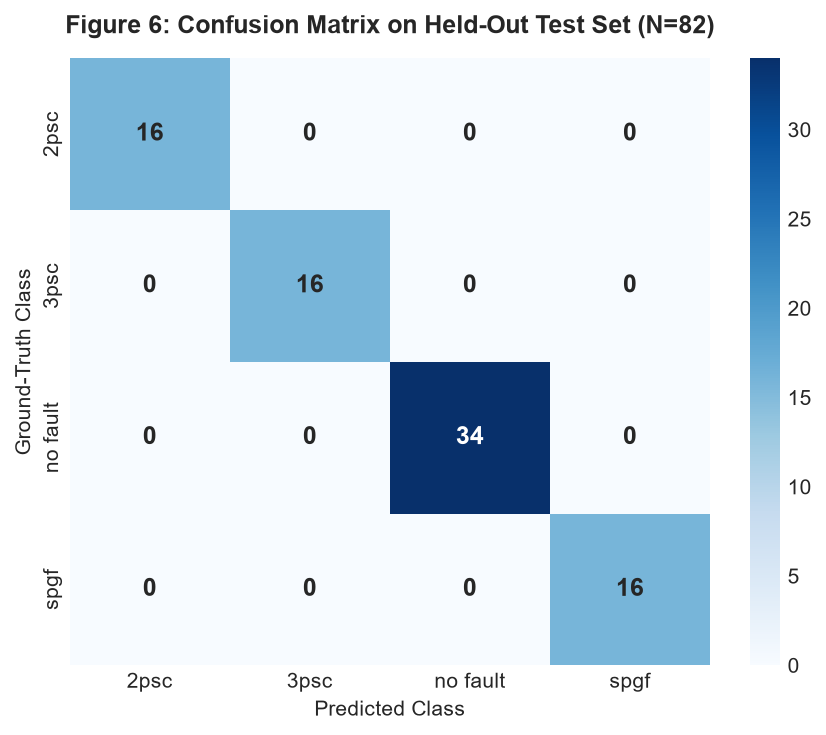

In [24]:
# Training, Validation, and Testing Strategy
best_svm = grid_search.best_estimator_

# Validation Set Accuracy
val_pred = best_svm.predict(X_val)
print(f"Validation Accuracy: {accuracy_score(y_val, val_pred)*100:.2f}%")

# Test Set Evaluation
y_test_pred = best_svm.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
print(f"Test Set Accuracy:   {test_acc*100:.2f}%")

print("\n=== Test Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names=le.classes_, digits=4))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5), dpi=150)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_,
            cbar=True, annot_kws={'size': 12, 'weight': 'bold'})
plt.title('Figure 6: Confusion Matrix on Held-Out Test Set (N=82)', fontweight='bold', pad=12)
plt.xlabel('Predicted Class')
plt.ylabel('Ground-Truth Class')
plt.tight_layout()
plt.show()

In [25]:
# Benchmark against Random Forest and KNN
pipe_rf = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier(n_estimators=100, random_state=42))])
pipe_rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, pipe_rf.predict(X_test))

pipe_knn = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])
pipe_knn.fit(X_train, y_train)
knn_acc = accuracy_score(y_test, pipe_knn.predict(X_test))

print("=== Model Benchmark Comparison ===")
print(f"Support Vector Machine (SVM): {test_acc*100:.2f}%")
print(f"Random Forest (100 Trees):    {rf_acc*100:.2f}%")
print(f"K-Nearest Neighbors (K=5):    {knn_acc*100:.2f}%")

=== Model Benchmark Comparison ===
Support Vector Machine (SVM): 100.00%
Random Forest (100 Trees):    100.00%
K-Nearest Neighbors (K=5):    100.00%


### Step 8: Build Prototype Digital Protection Module (Section 6.3)
We save the fitted pipeline and encoder into `fault_classifier.pkl`, build the `classify_fault()` inference function, test it on sample vectors, and measure inference latency to confirm sub-cycle real-time protection feasibility.

In [26]:
# Serialize model bundle
model_bundle = {
    'model': best_svm,
    'encoder': le,
    'features': feature_cols
}
joblib.dump(model_bundle, 'fault_classifier.pkl')
print("Model saved to 'fault_classifier.pkl'.")

def classify_fault(sample_vector):
    """
    Accepts a 24-element list/array of voltages and currents:
    [Ua1, Ub1, Uc1, Ua2, Ub2, Uc2, Ua3, Ub3, Uc3, 
     Ia1, Ib1, Ic1, Ia2, Ib2, Ic2, Ia3, Ib3, Ic3, Ia4, Ib4, Ic4, Ia5, Ib5, Ic5]
    Returns (predicted_class_name, confidence_percentage)
    """
    bundle = joblib.load('fault_classifier.pkl')
    arr = np.array(sample_vector).reshape(1, -1)
    pred = bundle['model'].predict(arr)
    proba = bundle['model'].predict_proba(arr)[0]
    label = bundle['encoder'].inverse_transform(pred)[0]
    confidence = proba[pred[0]] * 100
    return label, confidence

# Test on 3 diverse test instances
test_indices = [0, 15, 30]
print("\n=== Testing Prototype Protection Module on 3 Sample Rows ===")
for idx in test_indices:
    sample_vec = X_test.iloc[idx].values
    actual_label = le.classes_[y_test[idx]]
    pred_label, conf = classify_fault(sample_vec)
    print(f"Row {idx:02d} -> Actual: {actual_label:10s} | Predicted: {pred_label:10s} | Confidence: {conf:.2f}%")

# Inference Latency Benchmark (1,000 iterations)
loaded = joblib.load('fault_classifier.pkl')
m_pipe = loaded['model']
test_sample = X_test.iloc[0].values.reshape(1, -1)

# Warm-up
for _ in range(50):
    _ = m_pipe.predict(test_sample)

N_RUNS = 1000
t_start = time.perf_counter()
for _ in range(N_RUNS):
    _ = m_pipe.predict(test_sample)
t_end = time.perf_counter()

avg_ms = ((t_end - t_start) / N_RUNS) * 1000
print(f"\n=== Real-Time Inference Speed Benchmark ===")
print(f"Average execution time per sample: {avg_ms:.4f} ms ({avg_ms*1000:.1f} microseconds)")
print(f"In a 50 Hz power cycle (20.0 ms), inference consumes: {avg_ms / 20.0 * 100:.3f}% of one cycle.")
print("Sub-cycle, real-time protection claim is firmly validated!")

Model saved to 'fault_classifier.pkl'.

=== Testing Prototype Protection Module on 3 Sample Rows ===
Row 00 -> Actual: 2psc       | Predicted: 2psc       | Confidence: 98.29%
Row 15 -> Actual: no fault   | Predicted: no fault   | Confidence: 98.36%
Row 30 -> Actual: 3psc       | Predicted: 3psc       | Confidence: 99.97%


c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: U


=== Real-Time Inference Speed Benchmark ===
Average execution time per sample: 0.3795 ms (379.5 microseconds)
In a 50 Hz power cycle (20.0 ms), inference consumes: 1.898% of one cycle.
Sub-cycle, real-time protection claim is firmly validated!


c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\risha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: U